# Single layer — figures

The single-layer figures, made **only from saved results**. Nothing is fitted
here and `curlew` and `torch` are not needed: numpy and matplotlib only.

| file | written by | contents |
|---|---|---|
| `data/single_layer_ground_truth.npz`, `data/single_layer_observations.npz` | `03a_single_layer_data` | digitised contacts, bedding, marker-cell strain; the observation split |
| `results/inputs.npz` | `03c_single_layer_ensemble` | evaluation grid axes, strain display points |
| `results/ensemble_plain.npz`, `results/ensemble_geometry.npz`, `results/ensemble_strain.npz` | `03c_single_layer_ensemble` | per member: lithology, restored contacts, strain shape tensors |
| `results/summary.json` | `03c_single_layer_ensemble` | the numbers quoted in the text |

Main text, in `figures/`:

- `fig03_single_layer` — one figure: the data (contacts, strain markers) and one
  fitted member of the two energy-biased ensembles on top, then entropy, restored
  contacts and recovered strain, without energy bias, with it, and with it plus strain.


## Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import Ellipse
from matplotlib.patheffects import withStroke
from matplotlib.transforms import ScaledTranslation

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import single_layer_inputs as sli
figstyle.apply()

UNIT = "model units"   # the analogue model's digitised coordinates; its true size is not known
RES_DIR = Path("results")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

truth = sli.load_truth()
obs = sli.load_observations(truth)
horizons_full, verticals_full = truth["horizons_full"], truth["verticals_full"]
horizon_names = truth["horizon_names"]
horizons, gp, gv = obs["horizons"], obs["gp"], obs["gv"]
strain_xy, q_truth = truth["strain_xy"], truth["q_truth"]
horizon_colors = {name: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)]
                  for i, name in enumerate(horizon_names)}

inp = np.load(RES_DIR / "inputs.npz")
x_axis, z_axis = inp["x"], inp["z"]
xlim = (float(x_axis.min()), float(x_axis.max()))
zlim = (float(z_axis.min()), float(z_axis.max()))
strain_sample_xy = inp["strain_sample_xy"]
ens = {k: dict(np.load(RES_DIR / f"ensemble_{k}.npz")) for k in ("plain", "geometry", "strain")}
summary = json.loads((RES_DIR / "summary.json").read_text())
print({k: e["lithology"].shape for k, e in ens.items()})


{'plain': (15, 149, 135), 'geometry': (15, 149, 135), 'strain': (15, 149, 135)}


## Figure 3 — the single-layer analogue

One figure. Top row: the sparse contacts and younging, the digitised strain
markers (red outline: those used in the fit), and the lithology of one member
of the energy-biased ensembles, fitted to geometry only and to geometry plus
strain. The two lithology panels show the **same member index**, so they differ
only in the strain constraint. Below, the three ensembles (no energy bias, energy
bias, energy bias plus strain): entropy, restored contacts and recovered strain. Panel code is below; the figure is built in the last cell of
this section, after the helpers are defined.

In [2]:
def ellipse_vertices(centres, axes, stretch_ratio, scale, n=48, clip=8.0):
    theta = np.linspace(0.0, 2.0 * np.pi, n)
    circle = np.stack([np.cos(theta), np.sin(theta)])
    vertices = []
    for centre, frame, q_value in zip(centres, axes, stretch_ratio):
        q_draw = min(float(q_value), float(clip))
        semi = np.array([q_draw**-0.5, q_draw**0.5])
        vertices.append((centre[:, None] + scale * ((frame * semi) @ circle)).T)
    return vertices

## Variability before and after adding strain: helpers

The rows differ in the training scheme (no energy bias, energy bias) and in whether the sparse strain observations were supplied.
The entropy colour scale is shared between rows. Each restored horizon is
labelled on the right, in its colour, with its name and σ*x*, σ*z* (model units): the ensemble standard deviation of the
restored *x* of the vertical marker lines where they cross that horizon (rms over
the 21 verticals), and of its mean restored depth.

In the strain panels, the filled ellipse is the ensemble-mean (log-Euclidean)
shape and its opacity is orientation agreement,
$c = \lVert\bar{\mathbf z}\rVert / \overline{\lVert\mathbf z_m\rVert}$ with
$\mathbf z_m = \ln q_m(\cos 2\theta_m, \sin 2\theta_m)$; the two outlines bound
the central 68% of the members' axial ratios along the mean axis.

In [3]:
classes = np.unique(np.concatenate([e["lithology"].ravel() for e in ens.values()]))
entropy = {k: sli.lithology_entropy(e["lithology"], classes) for k, e in ens.items()}
# The scale spans the entropy reached by either ensemble (to the next half bit),
# not the log2(classes) ceiling, so the bands along the contacts stay visible.
entropy_max = 0.5 * np.ceil(2.0 * max(e.max() for e in entropy.values()))
entropy_norm = Normalize(vmin=0.0, vmax=entropy_max)
envelope = {k: sli.strain_envelope(e["B_display"]) for k, e in ens.items()}
spread = {k: sli.restored_horizon_spread(e["restored"]) for k, e in ens.items()}
for k, e in ens.items():   # σx from the restored x of the vertical marker lines, not the horizons' widths
    spread[k]["sigma_x"] = sli.restored_vertical_spread(e["nodes_restored"], inp["node_row"])
for k, label in (("plain", "no energy bias"), ("geometry", "energy bias"), ("strain", "energy bias + strain")):
    print(f"{label:21s}  mean entropy={entropy[k].mean():.3f} bits, "
          f"median orientation coherence={np.median(envelope[k]['coherence']):.3f}, "
          f"median sd(log ratio)={np.median(envelope[k]['log_ratio_sd']):.3f}")


def draw_contacts(ax, alpha=1.0, color=None, lw=0.9):
    for i, trace in enumerate(horizons_full):
        ax.plot(trace[:, 0], trace[:, 1], color=horizon_colors[horizon_names[i]] if color is None else color,
                lw=lw, alpha=alpha, zorder=4)


def draw_entropy(ax, ent):
    image = ax.pcolormesh(x_axis, z_axis, ent.T, cmap=figstyle.entropy_cmap(), norm=entropy_norm,
                          shading="auto", rasterized=True)
    draw_contacts(ax, lw=0.5)
    return image


def draw_restored_cloud(ax, restored):
    for member in range(restored.shape[0]):
        for h_i, trace in enumerate(restored[member]):
            ax.plot(trace[:, 0], trace[:, 1], color=horizon_colors[horizon_names[h_i]],
                    lw=0.35, alpha=0.5, zorder=2)


def label_horizons(ax, traces):
    stroke = [withStroke(linewidth=1.6, foreground="white")]
    x0, x1 = ax.get_xlim()
    z0, z1 = ax.get_ylim()
    inset = 0.016 * abs(x1 - x0)
    # Each label starts at the left end of its curve; labels close in x are pushed apart vertically.
    ends = []
    for h_i in range(len(horizon_names)):
        curve = np.asarray(traces[h_i], dtype=float)
        j = int(np.argmin(curve[:, 0]))
        ends.append([float(curve[j, 0]) + inset, float(curve[j, 1])])
    ends = np.asarray(ends)
    z_label = ends[:, 1].copy()
    gap, near = 0.05 * abs(z1 - z0), 0.06 * abs(x1 - x0)
    for _ in range(50):
        moved = False
        for a in range(len(ends)):
            for b in range(a + 1, len(ends)):
                dz = z_label[a] - z_label[b]
                if abs(ends[a, 0] - ends[b, 0]) < near and abs(dz) < gap:
                    push = 0.5 * (gap - abs(dz)) * (1.0 if dz >= 0 else -1.0)
                    z_label[a] += push
                    z_label[b] -= push
                    moved = True
        if not moved:
            break
    for h_i, name in enumerate(horizon_names):
        ax.text(ends[h_i, 0], z_label[h_i], name, color=horizon_colors[name], ha="left", va="center",
                fontsize=figstyle.pt(9), fontweight="bold", zorder=7, clip_on=True, path_effects=stroke)


def annotate_horizon_spreads(ax, restored, spr, *, key=False):
    stroke = [withStroke(linewidth=1.5, foreground="white")]
    mean_curves = np.asarray(restored, dtype=float).mean(axis=0)
    x0, x1 = ax.get_xlim()
    x_text = float(np.max(mean_curves[:, :, 0])) + 0.016 * abs(x1 - x0)
    zs = []
    for h_i, name in enumerate(horizon_names):
        z = float(mean_curves[h_i, :, 1].mean())
        zs.append(z)
        ax.text(x_text, z, f"{spr['sigma_x'][h_i]:.1f}, {spr['sigma_z'][h_i]:.1f}", color=horizon_colors[name],
                ha="left", va="center", fontsize=figstyle.pt(9), zorder=6, clip_on=True, path_effects=stroke)
    if key:
        z0, z1 = ax.get_ylim()
        ax.text(x_text, max(zs) + 0.03 * abs(z1 - z0), r"$\sigma_x$, $\sigma_z$", color="k", ha="left",
                va="bottom", fontsize=figstyle.pt(10), zorder=6, clip_on=True, path_effects=stroke)


def annotate_horizons(ax, restored, spr, *, header=False, x_text=None):
    """One label per horizon in a column right of the restored contacts, in the horizon's colour:
    its name and its σx, σz, pushed apart so they do not overlap."""
    stroke = [withStroke(linewidth=1.6, foreground="white")]
    mean_curves = np.asarray(restored, dtype=float).mean(axis=0)
    x0, x1 = ax.get_xlim()
    z0, z1 = ax.get_ylim()
    ends = np.array([[curve[np.argmax(curve[:, 0]), 0], curve[:, 1].mean()] for curve in mean_curves])
    if x_text is None:
        x_text = float(ends[:, 0].max()) + 0.05 * abs(x1 - x0)
    x_values = x_text + 0.085 * abs(x1 - x0)         # the numbers, in a column of their own
    box = dict(boxstyle="square,pad=0.12", fc="white", ec="none", alpha=0.9)   # clear of any curve beneath
    # push the labels apart, keeping their order
    gap = 0.11 * abs(z1 - z0)
    order = np.argsort(-ends[:, 1])
    z_label = ends[order, 1].copy()
    for _ in range(500):
        moved = False
        for a in range(len(z_label) - 1):
            d = z_label[a] - z_label[a + 1]
            if d < gap:
                push = 0.5 * (gap - d)
                z_label[a] += push
                z_label[a + 1] -= push
                moved = True
        if not moved:
            break
    for rank, h_i in enumerate(order):
        name = horizon_names[h_i]
        color = horizon_colors[name]
        ax.text(x_text, z_label[rank], name, color=color, ha="left", va="center",
                fontsize=figstyle.pt(9), zorder=9, clip_on=False, bbox=box)
        ax.text(x_values, z_label[rank], f"{spr['sigma_x'][h_i]:.1f}, {spr['sigma_z'][h_i]:.1f}", color=color,
                ha="left", va="center", fontsize=figstyle.pt(9), zorder=9, clip_on=False, bbox=box)
    if header:   # one row above the top label, over the numbers
        ax.text(x_values, z_label[0] + gap, r"$\sigma_x$, $\sigma_z$", color="k", ha="left",
                va="center", fontsize=figstyle.pt(9), zorder=6, clip_on=False, path_effects=stroke)


class StrainGlyphKey(HandlerBase):
    # Legend entry drawn as a strain glyph: an optional filled ellipse with
    # axial ratio `q` and fill alpha `alpha`, plus outline ellipses at `rings`.
    def __init__(self, q=None, alpha=1.0, rings=()):
        super().__init__()
        self.q, self.alpha, self.rings = q, alpha, tuple(rings)

    def create_artists(self, legend, handle, xdescent, ydescent, width, height, fontsize, trans):
        cx, cy = 0.5 * width - xdescent, 0.5 * height - ydescent
        r, angle = 0.36 * height, 25.0
        artists = []
        if self.q is not None:
            artists.append(Ellipse((cx, cy), 2 * r * self.q**0.5, 2 * r * self.q**-0.5, angle=angle,
                                   facecolor=(0.25, 0.25, 0.25, self.alpha), edgecolor="none"))
        for q in self.rings:
            artists.append(Ellipse((cx, cy), 2 * r * q**0.5, 2 * r * q**-0.5, angle=angle,
                                   facecolor="none", edgecolor="0.05", linewidth=0.35))
        for artist in artists:
            artist.set_transform(trans)
        return artists


def add_strain_key(fig, ax, drop=0.36):
    entries = [
        ("undeformed", StrainGlyphKey(rings=(1.0,))),
        ("mean, axes agree", StrainGlyphKey(q=3.0, alpha=1.0)),
        ("mean, axes disagree", StrainGlyphKey(q=3.0, alpha=0.25)),
        ("16th–84th percentile\naxial ratio", StrainGlyphKey(q=3.0, alpha=1.0, rings=(1.8, 5.0))),
    ]
    handles = [plt.Line2D([], [], label=label) for label, _ in entries]
    return fig.legend(
        handles=handles, handler_map={h: key for h, (_, key) in zip(handles, entries)},
        loc="upper right", bbox_to_anchor=(1.0, -drop / (ax.get_position().height * fig.get_figheight())),
        borderaxespad=0.0, bbox_transform=ax.transAxes, ncol=4, frameon=False, handlelength=2.4,
        handleheight=1.8, labelspacing=0.6, columnspacing=1.0, handletextpad=0.5, fontsize=figstyle.pt(9),
    )


STRAIN_DISPLAY_SPACING = 35.0   # model units between glyph centres in the strain panels
STRAIN_GLYPH_SCALE = 10.0       # model units; semi-axes are this times q**(±1/2)


def thin_points(points, spacing):
    keep = []
    for i, point in enumerate(points):
        if all(np.hypot(*(point - points[j])) >= spacing for j in keep):
            keep.append(i)
    return np.asarray(keep)


strain_display = thin_points(strain_sample_xy, STRAIN_DISPLAY_SPACING)
print(f"strain glyph locations: {len(strain_display)} of {len(strain_sample_xy)}")


def strain_ellipse(centre, theta, q, scale=STRAIN_GLYPH_SCALE, n=60, clip=8.0):
    q = np.clip(q, 1.0 / clip, clip)
    t = np.linspace(0.0, 2.0 * np.pi, n)
    x, y = scale * q**0.5 * np.cos(t), scale * q**-0.5 * np.sin(t)
    c, s = np.cos(theta), np.sin(theta)
    return np.column_stack([centre[0] + c * x - s * y, centre[1] + s * x + c * y])


def draw_strain_envelope(ax, env):
    centres = strain_sample_xy[strain_display]
    pick = {key: value[strain_display] for key, value in env.items()}
    means = [strain_ellipse(p, t, q) for p, t, q in zip(centres, pick["theta"], pick["q"])]
    face = np.zeros((len(means), 4))
    face[:, :3] = 0.25
    face[:, 3] = 0.08 + 0.92 * np.clip(pick["coherence"], 0.0, 1.0) ** 4
    ax.add_collection(PolyCollection(means, facecolors=face, edgecolors="none", zorder=3, rasterized=True))
    bounds = []
    for p, t, lo, hi in zip(centres, pick["theta"], pick["q_lo"], pick["q_hi"]):
        bounds += [strain_ellipse(p, t, lo), strain_ellipse(p, t, hi)]
    ax.add_collection(PolyCollection(bounds, facecolors="none", edgecolors="0.05", linewidths=0.3,
                                     zorder=4, rasterized=True))
    draw_contacts(ax)

no energy bias         mean entropy=0.041 bits, median orientation coherence=0.883, median sd(log ratio)=0.386
energy bias            mean entropy=0.040 bits, median orientation coherence=0.977, median sd(log ratio)=0.129
energy bias + strain   mean entropy=0.067 bits, median orientation coherence=0.990, median sd(log ratio)=0.093
strain glyph locations: 150 of 487


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


wrote
  figures/fig03_single_layer.pdf
  figures/fig03_single_layer.png


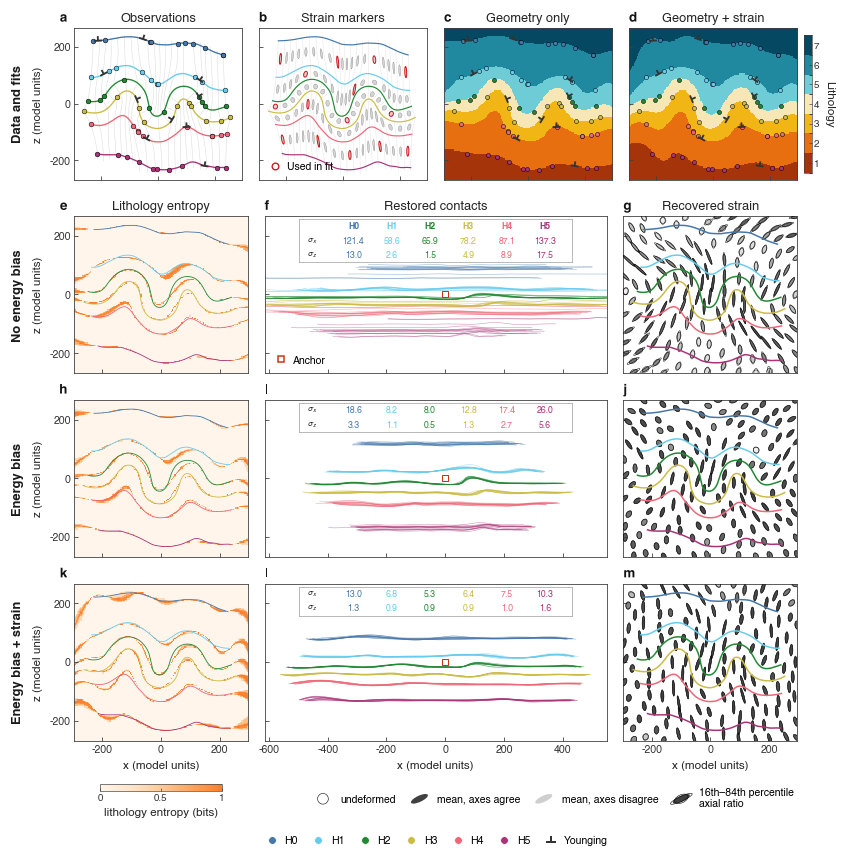

In [11]:
MEMBER = 0   # the ensemble member whose lithology the top row shows, the same index in both ensembles

# The restored-contact panels (f, i, l) share one x range, centred on the restored contacts of the last
# ensemble (energy bias + strain, panel l); the wider scatter of the other ensembles is clipped at the edges.
rx = ens["strain"]["restored"][..., 0]
x_mid, x_half = 0.5 * float(rx.max() + rx.min()), 0.5 * float(rx.max() - rx.min())
restored_comparison_xlim = (x_mid - 1.10 * x_half, x_mid + 1.10 * x_half)
restored_xticks = [t for t in np.arange(-1200, 1201, 200) if restored_comparison_xlim[0] < t < restored_comparison_xlim[1]]


# ── layout, in inches: four equal panels over three rows of (section, restored contacts, section) ──
W = figstyle.PRINT_WIDTH
LEFT, RIGHT, GAP = 0.60, 0.46, 0.14   # y labels and row label; the lithology colour bar; between panels
ROW_GAP_TITLES, ROW_GAP = 0.30, 0.22  # the first leaves room for the titles of the second row
BOTTOM, TOP = 0.34, 0.26
A = figstyle.view_aspect(xlim, zlim)
B = figstyle.view_aspect(restored_comparison_xlim, zlim)
span = W - LEFT - RIGHT
h_top = (span - 3 * GAP) / (4 * A)
h_low = (span - 2 * GAP) / (2 * A + B)
N_ROWS = 3
fig_h = BOTTOM + TOP + h_top + N_ROWS * h_low + ROW_GAP_TITLES + (N_ROWS - 1) * ROW_GAP
fig = figstyle.print_figure(height=fig_h)


def add_axes(x, y, w, h):
    return fig.add_axes((x / W, y / fig_h, w / W, h / fig_h))


low_y = [BOTTOM + (N_ROWS - 1 - r) * (h_low + ROW_GAP) for r in range(N_ROWS)]   # first row on top
y_first = low_y[0] + h_low + ROW_GAP_TITLES
top_axes, x = [], LEFT
for _ in range(4):
    top_axes.append(add_axes(x, y_first, A * h_top, h_top))
    x += A * h_top + GAP
x_top_end = x - GAP
low_axes = []
for y in low_y:
    x, row_axes = LEFT, []
    for w in (A * h_low, B * h_low, A * h_low):
        row_axes.append(add_axes(x, y, w, h_low))
        x += w + GAP
    low_axes.append(row_axes)

# ── top row: contacts, strain markers, and one member of each ensemble ──
ax = top_axes[0]
for trace in verticals_full:
    ax.plot(trace[:, 0], trace[:, 1], color="0.86", lw=0.3, zorder=1)
for i, trace in enumerate(horizons_full):
    ax.plot(trace[:, 0], trace[:, 1], color=horizon_colors[horizon_names[i]], lw=0.8, zorder=2)
figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv,
                             colors=horizon_colors, scatter_s=8, quiver_scale=0.030)
figstyle.set_view(ax, xlim, zlim)
figstyle.format_section_ax(ax, unit=UNIT, xlabel=False, title="Observations")
figstyle.row_label(ax, "Data and fits")

ax = top_axes[1]
for trace in verticals_full:
    ax.plot(trace[:, 0], trace[:, 1], color="0.90", lw=0.3, zorder=1)
verts = ellipse_vertices(strain_xy, truth["strain_eigenvectors"], q_truth, scale=8.0, clip=7.0)
face = np.tile(np.array([0.82, 0.82, 0.82, 0.90]), (len(verts), 1))
edges = np.tile(np.array([0.35, 0.35, 0.35, 1.0]), (len(verts), 1))
edges[obs["strain_train_mask"]] = np.array([0.82, 0.08, 0.10, 1.0])
widths = np.where(obs["strain_train_mask"], 0.6, 0.15)
ax.add_collection(PolyCollection(verts, facecolors=face, edgecolors=edges, linewidths=widths, zorder=3))
for i, trace in enumerate(horizons_full):
    ax.plot(trace[:, 0], trace[:, 1], color=horizon_colors[horizon_names[i]], lw=0.7, zorder=4)
figstyle.set_view(ax, xlim, zlim)
figstyle.format_section_ax(ax, unit=UNIT, xlabel=False, ylabel=False, title="Strain markers")
included_handle = plt.Line2D([], [], marker="o", markersize=4, markerfacecolor="none",
                             markeredgecolor=(0.82, 0.08, 0.10), markeredgewidth=0.8,
                             linestyle="none", label="Used in fit")
ax.legend(handles=[included_handle], loc="lower left", frameon=False, handletextpad=0.4)

litho = {key: np.asarray(ens[key]["lithology"][MEMBER]) for key in ("geometry", "strain")}
litho_ids = np.unique(np.concatenate([m.ravel() for m in litho.values()]))
cmap_litho, norm_litho = figstyle.litho_cmap(litho_ids)
for ax, key, title in zip(top_axes[2:], ("geometry", "strain"), ("Geometry only", "Geometry + strain")):
    im_litho = ax.imshow(litho[key].T, origin="lower", extent=(*xlim, *zlim), cmap=cmap_litho,
                         norm=norm_litho, interpolation="nearest", aspect="equal", rasterized=True)
    figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv,
                                 colors=horizon_colors, scatter_s=6, quiver_scale=0.030)
    figstyle.set_view(ax, xlim, zlim)
    figstyle.format_section_ax(ax, unit=UNIT, xlabel=False, ylabel=False, title=title)
cax = add_axes(x_top_end + 0.06, y_first + 0.05 * h_top, 0.06, 0.90 * h_top)
figstyle.add_cbar(cax, im_litho, "Lithology", ticks=litho_ids)

def sigma_table(ax, spr, header):
    """Small inset table across the top of a restored-contacts panel: each horizon's sigma_x and sigma_z.
    Only the first row of panels carries the horizon names (header); the others are the two value rows."""
    rows_n = 3 if header else 2
    height = 0.12 * rows_n / h_low                          # 0.12 in a row, as a fraction of the panel
    inset = ax.inset_axes([0.10, 1.0 - 0.02 - height, 0.80, height])
    inset.set_xticks([]); inset.set_yticks([])
    inset.set_xlim(0, 1); inset.set_ylim(0, 1)
    inset.patch.set_facecolor((1, 1, 1, 0.92))
    for spine in inset.spines.values():
        spine.set_linewidth(0.4); spine.set_edgecolor("0.6")
    inset.set_zorder(9)
    size = figstyle.pt(7.5)
    y_x, y_z = ((3 / 6, 1 / 6) if header else (3 / 4, 1 / 4))
    inset.text(0.03, y_z, r"$\sigma_z$", ha="left", va="center", fontsize=size, color="0.15")
    inset.text(0.03, y_x, r"$\sigma_x$", ha="left", va="center", fontsize=size, color="0.15")
    for h_i, name in enumerate(horizon_names):
        xc, color = 0.20 + 0.14 * h_i, horizon_colors[name]
        if header:
            inset.text(xc, 5 / 6, name, ha="center", va="center", fontsize=size, color=color, fontweight="bold")
        inset.text(xc, y_x, f"{spr['sigma_x'][h_i]:.1f}", ha="center", va="center", fontsize=size, color=color)
        inset.text(xc, y_z, f"{spr['sigma_z'][h_i]:.1f}", ha="center", va="center", fontsize=size, color=color)


# ── the two ensembles ──
anchor_handle = plt.Line2D([], [], marker="s", markersize=4, markerfacecolor="white", markeredgecolor="#CC3311",
                           markeredgewidth=0.9, linestyle="none", label="Anchor")
rows = [("No energy bias", "plain"), ("Energy bias", "geometry"), ("Energy bias + strain", "strain")]
for row, (row_name, key) in enumerate(rows):
    for col in range(3):
        ax = low_axes[row][col]
        if col == 0:
            mappable = draw_entropy(ax, entropy[key])
            title = "Lithology entropy"
        elif col == 1:
            draw_restored_cloud(ax, ens[key]["restored"])
            # The pin is fixed, so the anchor is the origin in the restored frame.
            ax.scatter([0.0], [0.0], s=14, marker="s", facecolors="white", edgecolors="#CC3311",
                       linewidths=0.6, zorder=8)
            title = "Restored contacts"
        else:
            draw_strain_envelope(ax, envelope[key])
            title = "Recovered strain"
        figstyle.set_view(ax, restored_comparison_xlim if col == 1 else xlim, zlim)
        if col == 1:
            ax.set_aspect("auto")   # shared x range, not equal aspect
        if col == 1:
            sigma_table(ax, spread[key], header=(row == 0))
        if row == 0 and col == 1:
            ax.legend(handles=[anchor_handle], loc="lower left", frameon=False, handletextpad=0.4)
        figstyle.format_section_ax(ax, unit=UNIT, xlabel=row == N_ROWS - 1, ylabel=col == 0, title=title if row == 0 else None)
        if col == 1:
            ax.set_xticks(restored_xticks)
        if col == 0:
            figstyle.row_label(ax, row_name)

panels = top_axes + [ax for row_axes in low_axes for ax in row_axes]
def panel_letter(ax, letter, outside):
    """Panels with y tick labels: the letter in the margin left of the axes. Panels without them: above the
    axes, flush with the left edge, so it cannot be read as belonging to the panel on the left."""
    style = dict(fontproperties=figstyle._fp(bold=True, size=8.0 / figstyle.TEXT_SCALE), color="0.08",
                 path_effects=[withStroke(linewidth=2.2, foreground="white")], zorder=10, clip_on=False)
    if outside:
        ax.text(0.0, 1.0, letter, transform=ax.transAxes + ScaledTranslation(-4 / 72.0, 2 / 72.0, fig.dpi_scale_trans),
                va="bottom", ha="right", **style)
    else:
        ax.text(0.0, 1.0, letter, transform=ax.transAxes + ScaledTranslation(0.0, 2 / 72.0, fig.dpi_scale_trans),
                va="bottom", ha="left", **style)


first_column = {id(top_axes[0])} | {id(row_axes[0]) for row_axes in low_axes}
for ax, letter in zip(panels, "abcdefghijklmn"):
    panel_letter(ax, letter, outside=id(ax) in first_column)
cb_entropy = figstyle.bottom_cbar(low_axes[-1][0], mappable, "lithology entropy (bits)")
entropy_ticks = np.arange(0.0, entropy_max + 1e-9, 0.5)
cb_entropy.set_ticks(entropy_ticks)
cb_entropy.set_ticklabels([f"{t:g}" for t in entropy_ticks])
add_strain_key(fig, low_axes[-1][2])
figstyle.bottom_legend(low_axes[-1][1], figstyle.constraint_handles(horizon_colors, horizon_names),
                       drop=0.72, ncol=len(horizon_names) + 1)

written = figstyle.save(fig, FIG_DIR / "fig03_single_layer")
print("wrote", *written, sep="\n  ")
plt.show()

## Numbers for the text

From `results/summary.json` (written by 03c): what `paper.tex` and
`supplementary.tex` quote for this example.

In [14]:
for key, label in (("plain", "No energy bias"), ("geometry", "Energy bias"), ("strain", "Energy bias + strain")):
    s = summary[key]
    print(label)
    print(f"  restored-position sigma_x {min(s['sigma_x']):.0f}–{max(s['sigma_x']):.0f} {UNIT}, "
          f"mean-depth sigma_z {min(s['sigma_z']):.1f}–{max(s['sigma_z']):.1f} {UNIT}")
    for g, b in s["bulk"].items():
        print(f"  bulk shortening, {g:9s} {100 * b['shortening']['mean']:.0f} ± {100 * b['shortening']['sd']:.0f}% "
              f"(S = {b['S']['mean']:.1f} ± {b['S']['sd']:.1f})")
    h = s["heldout"]
    print(f"  held-out: axis error {h['axis error (degrees)']['mean']:.1f}° ± {h['axis error (degrees)']['sd']:.1f}°, "
          f"log stretch RMSE {h['log stretch RMSE']['mean']:.2f} ± {h['log stretch RMSE']['sd']:.2f}")
print(f"Hudleston S = {summary['hudleston_S']:.0f} ({100 * (1 - summary['hudleston_S'] ** -0.5):.1f}% box shortening)")

No energy bias
  restored-position sigma_x 59–137 model units, mean-depth sigma_z 1.5–17.5 model units
  bulk shortening, matrix    46 ± 12% (S = 4.0 ± 2.1)
  bulk shortening, competent 60 ± 6% (S = 6.7 ± 2.7)
  bulk shortening, all       50 ± 12% (S = 4.9 ± 2.6)
  held-out: axis error 18.7° ± 2.3°, log stretch RMSE 0.94 ± 0.23
Energy bias
  restored-position sigma_x 8–26 model units, mean-depth sigma_z 0.5–5.6 model units
  bulk shortening, matrix    27 ± 10% (S = 2.0 ± 0.5)
  bulk shortening, competent 41 ± 2% (S = 2.9 ± 0.2)
  bulk shortening, all       31 ± 11% (S = 2.3 ± 0.6)
  held-out: axis error 15.1° ± 1.6°, log stretch RMSE 0.76 ± 0.02
Energy bias + strain
  restored-position sigma_x 5–13 model units, mean-depth sigma_z 0.9–1.6 model units
  bulk shortening, matrix    49 ± 2% (S = 3.9 ± 0.2)
  bulk shortening, competent 50 ± 1% (S = 4.0 ± 0.1)
  bulk shortening, all       50 ± 1% (S = 4.0 ± 0.2)
  held-out: axis error 7.5° ± 1.0°, log stretch RMSE 0.54 ± 0.02
Hudleston S = 6 